## Resnet transfer learning with Rock-Paper-Scissor

This notebook demonstrates transfer learning using ResNet50V2 on the RockPaperScissor dataset from Tensorflow Datasets

In [7]:
# !pip install importlib_resources

In [11]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

In [12]:
(ds_train, ds_test), ds_info= tfds.load(
    'rock_paper_scissors',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True
)
print(ds_info)

tfds.core.DatasetInfo(
    name='rock_paper_scissors',
    full_name='rock_paper_scissors/3.0.0',
    description="""
    Images of hands playing rock, paper, scissor game.
    """,
    homepage='http://laurencemoroney.com/rock-paper-scissors-dataset',
    data_dir='/root/tensorflow_datasets/rock_paper_scissors/3.0.0',
    file_format=tfrecord,
    download_size=219.53 MiB,
    dataset_size=219.23 MiB,
    features=FeaturesDict({
        'image': Image(shape=(300, 300, 3), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=3),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=372, num_shards=1>,
        'train': <SplitInfo num_examples=2520, num_shards=2>,
    },
    citation="""@ONLINE {rps,
    author = "Laurence Moroney",
    title = "Rock, Paper, Scissors Dataset",
    month = "feb",
    year = "2019",
    url = "http://laurencemoroney.com/rock

In [13]:
# step 3 : normalize and batch the  data
def normalize_img(image, label):
    return tf.cast(image, tf.float32) / 255.0, label

batch_size= 64

ds_train=ds_train.map(normalize_img, num_parallel_calls=tf.data.AUTOTUNE)
ds_train=ds_train.cache().shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)

ds_test=ds_test.map(normalize_img, num_parallel_calls=tf.data.AUTOTUNE)
ds_test=ds_test.cache().shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)

In [15]:
# step 4: define the transfer learning model
base_model=tf.keras.applications.ResNet50V2(
    input_shape=(300, 300, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable=False
model=tf.keras.Sequential([
    tf.keras.layers.Resizing(300, 300),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 10, 10, 2048)   │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,564,800 (89.89 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,564,800 (89.89 MB)

In [17]:
history=model.fit(ds_train, validation_data=ds_test, epochs=10)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 342ms/step - accuracy: 1.0000 - loss: 0.0149 - val_accuracy: 0.7661 - val_loss: 0.4746
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 15s 374ms/step - accuracy: 1.0000 - loss: 0.0133 - val_accuracy: 0.7581 - val_loss: 0.5143
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 360ms/step - accuracy: 1.0000 - loss: 0.0117 - val_accuracy: 0.7634 - val_loss: 0.4969
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 357ms/step - accuracy: 1.0000 - loss: 0.0105 - val_accuracy: 0.7796 - val_loss: 0.4673
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 335ms/step - accuracy: 1.0000 - loss: 0.0095 - val_accuracy: 0.7715 - val_loss: 0.4774
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 21s 343ms/step - accuracy: 1.0000 - loss: 0.0087 - val_accuracy: 0.7769 - val_loss: 0.4722
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 358ms/step - accuracy: 1.0000 - loss: 0.0078 - val_accuracy: 0.7688 - val_loss: 0.4982
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 15s 364ms/step - accuracy: 1.0000 - loss: 0.0072 - val_accu

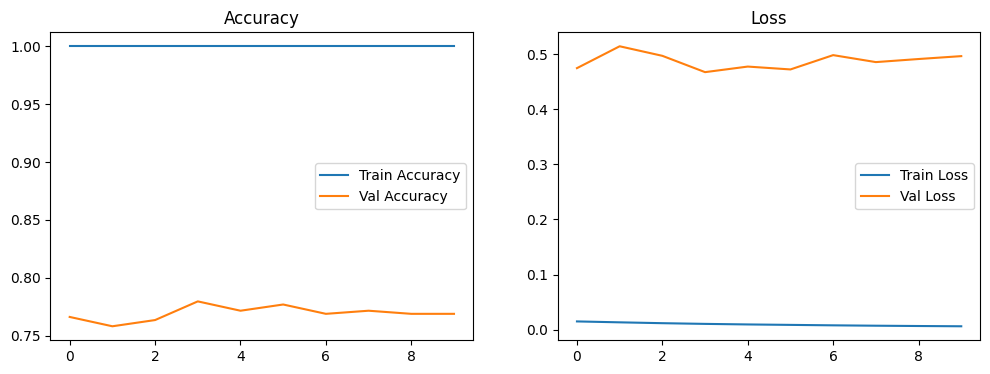

In [18]:
# 📈 Step 6: Visualize Training Results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')

plt.show()

In [19]:
# 🧪 Step 7: Evaluate on Test Set
test_loss, test_acc = model.evaluate(ds_test)
print(f"Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 277ms/step - accuracy: 0.7688 - loss: 0.4964
Test Accuracy: 0.7688, Test Loss: 0.4964


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


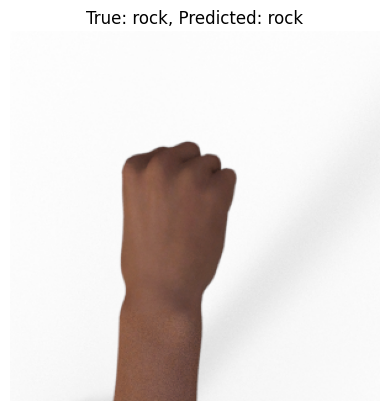

In [20]:
# 🔍 Step 8: Inference on a Random Test Image
import random
import tensorflow_datasets as tfds

# Load test data again without batching
raw_test_ds = tfds.load('rock_paper_scissors', split='test', as_supervised=True)

# Pick a random test sample
sample_list = list(raw_test_ds)
sample_image, sample_label = random.choice(sample_list)

# Preprocess image
input_image = tf.image.resize(sample_image, (300, 300)) / 255.0
input_image = tf.expand_dims(input_image, axis=0)  # Add batch dimension

# Predict
pred = model.predict(input_image)
predicted_class = tf.argmax(pred[0]).numpy()

# Class labels
class_names = ds_info.features['label'].names

# Display
plt.imshow(sample_image)
plt.title(f"True: {class_names[sample_label]}, Predicted: {class_names[predicted_class]}")
plt.axis('off')
plt.show()